Dataset Loaded Successfully!
--------------------------------------------------
TC01: Dataset Loading - PASS
Rows: 7084
Columns: 24
TC02: Dataset Dimensions - PASS

Missing Values:
Delivery_Date         106
Age                   142
Income                253
Discount               71
Customer_Rating       428
Satisfaction_Level    179
dtype: int64
TC03: Missing Value Identification - PASS

Duplicate Records: 61
Records After Removing Duplicates: 7023
TC04: Duplicate Record Removal - PASS

Valid Dates: 6540
Invalid or Missing Dates: 483
TC05: Date Validation - PASS

Regional Sales:
Region
East     19838387.16
NORTH      174995.60
Nort       156460.02
North    17631291.56
South    18394141.53
Sth        334996.61
WEST       298958.05
West     19383217.15
east       200643.46
north      158302.77
south      250395.14
west       137355.06
Name: Sales, dtype: float64
TC07: Regional Sales Analysis - PASS


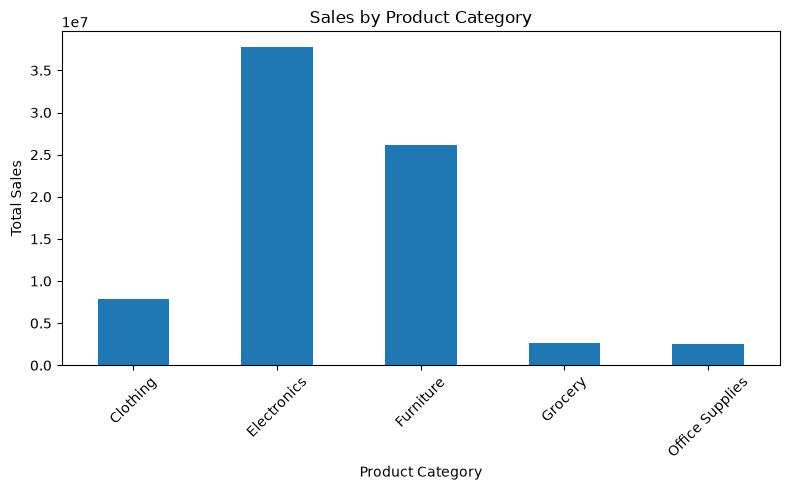

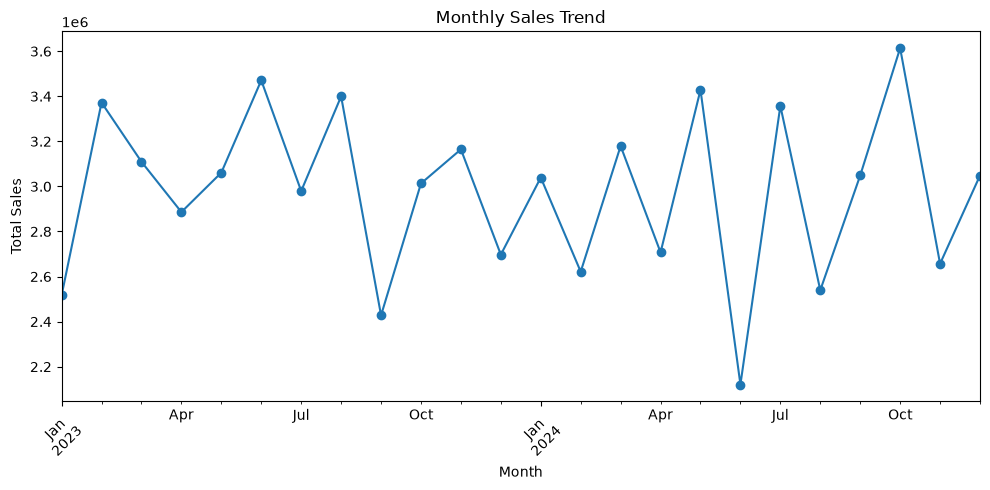

TC08: Sales Visualization - PASS

Correlation Matrix:
                      Age    Income  Quantity  Unit_Price  Discount     Sales  \
Age              1.000000 -0.008774  0.008087    0.016390  0.015971  0.009619   
Income          -0.008774  1.000000 -0.006084    0.022160  0.005512  0.009571   
Quantity         0.008087 -0.006084  1.000000    0.007932  0.008314  0.372063   
Unit_Price       0.016390  0.022160  0.007932    1.000000 -0.012660  0.824805   
Discount         0.015971  0.005512  0.008314   -0.012660  1.000000 -0.109862   
Sales            0.009619  0.009571  0.372063    0.824805 -0.109862  1.000000   
Cost             0.012165  0.008772  0.369015    0.817596 -0.107867  0.991410   
Profit           0.004020  0.010671  0.358746    0.796187 -0.108128  0.965004   
Customer_Rating  0.039041  0.015703 -0.018746   -0.000106  0.000883 -0.002608   

                     Cost    Profit  Customer_Rating  
Age              0.012165  0.004020         0.039041  
Income           0.008772

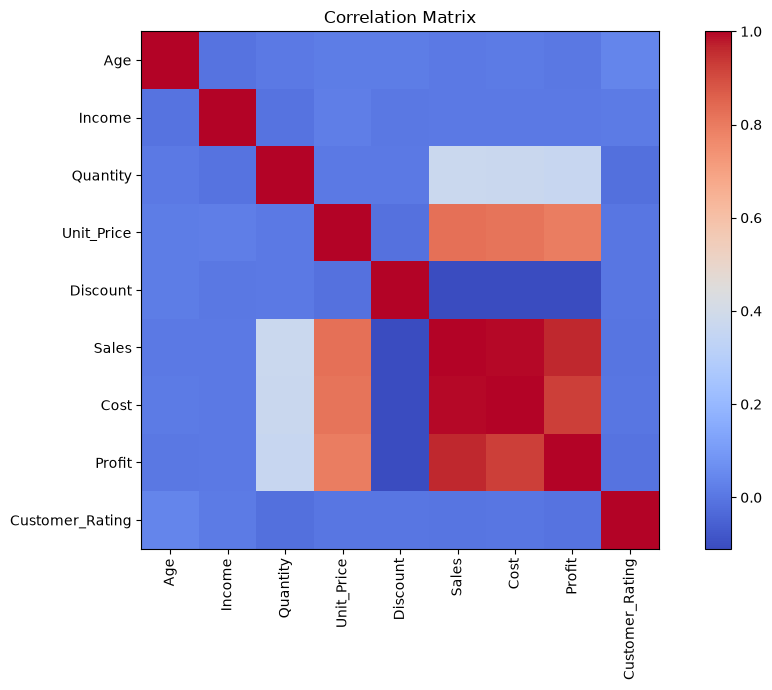

TC09: Correlation Matrix - PASS

Overall Sales: 76959144.10999998
Regional Sales Total: 76959144.11
TC10: Final Analysis Consistency - PASS

ALL TEST CASES COMPLETED


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# TC01: Load Dataset
def load_dataset():
    return pd.read_csv("retail_customer_sales_dataset.csv")

df = load_dataset()

print("Dataset Loaded Successfully!")
print("-" * 50)

# Function to display test results
def test_result(test_id, description, status):
    print(f"{test_id}: {description} - {status}")


# TC01: Check Dataset Loading
try:
    assert not df.empty
    test_result("TC01", "Dataset Loading", "PASS")
except Exception as e:
    test_result("TC01", "Dataset Loading", "FAIL")


# TC02: Check Dataset Dimensions
try:
    rows, columns = df.shape
    assert rows > 0 and columns > 0
    print("Rows:", rows)
    print("Columns:", columns)
    test_result("TC02", "Dataset Dimensions", "PASS")
except Exception:
    test_result("TC02", "Dataset Dimensions", "FAIL")


# TC03: Identify Missing Values
try:
    missing_values = df.isnull().sum()
    print("\nMissing Values:")
    print(missing_values[missing_values > 0])
    test_result("TC03", "Missing Value Identification", "PASS")
except Exception:
    test_result("TC03", "Missing Value Identification", "FAIL")


# TC04: Remove Duplicate Records
try:
    duplicate_count = df.duplicated().sum()
    cleaned_df = df.drop_duplicates()

    print("\nDuplicate Records:", duplicate_count)
    print("Records After Removing Duplicates:", len(cleaned_df))

    assert cleaned_df.duplicated().sum() == 0
    test_result("TC04", "Duplicate Record Removal", "PASS")
except Exception:
    test_result("TC04", "Duplicate Record Removal", "FAIL")


# TC05: Validate Date Column
try:
    cleaned_df["Order_Date"] = pd.to_datetime(
        cleaned_df["Order_Date"], errors="coerce"
    )

    valid_dates = cleaned_df["Order_Date"].notna().sum()
    invalid_dates = cleaned_df["Order_Date"].isna().sum()

    print("\nValid Dates:", valid_dates)
    print("Invalid or Missing Dates:", invalid_dates)

    assert valid_dates > 0
    test_result("TC05", "Date Validation", "PASS")
except Exception:
    test_result("TC05", "Date Validation", "FAIL")





# TC07: Analyze Regional Sales
try:
    regional_sales = cleaned_df.groupby(
        "Region"
    )["Sales"].sum()

    print("\nRegional Sales:")
    print(regional_sales)

    assert len(regional_sales) > 0
    test_result("TC07", "Regional Sales Analysis", "PASS")
except Exception:
    test_result("TC07", "Regional Sales Analysis", "FAIL")


# TC08: Generate Sales Visualizations
try:
    # Category-wise sales
    category_sales = cleaned_df.groupby(
        "Product_Category"
    )["Sales"].sum()

    category_sales.plot(kind="bar", figsize=(8, 5))
    plt.title("Sales by Product Category")
    plt.xlabel("Product Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Monthly sales trend
    monthly_sales = cleaned_df.dropna(
        subset=["Order_Date"]
    ).copy()

    monthly_sales["Month"] = (
        monthly_sales["Order_Date"].dt.to_period("M")
    )

    monthly_sales = monthly_sales.groupby(
        "Month"
    )["Sales"].sum()

    monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    test_result("TC08", "Sales Visualization", "PASS")
except Exception as e:
    print("Error:", e)
    test_result("TC08", "Sales Visualization", "FAIL")


# TC09: Generate Correlation Matrix
try:
    numeric_data = cleaned_df.select_dtypes(
        include="number"
    )

    correlation_matrix = numeric_data.corr()

    print("\nCorrelation Matrix:")
    print(correlation_matrix)

    plt.figure(figsize=(10, 7))
    plt.imshow(correlation_matrix, cmap="coolwarm")
    plt.colorbar()
    plt.xticks(
        range(len(correlation_matrix.columns)),
        correlation_matrix.columns,
        rotation=90
    )
    plt.yticks(
        range(len(correlation_matrix.columns)),
        correlation_matrix.columns
    )
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    assert not correlation_matrix.empty
    test_result("TC09", "Correlation Matrix", "PASS")
except Exception:
    test_result("TC09", "Correlation Matrix", "FAIL")


# TC10: Check Consistency of Final Analysis
try:
    overall_sales = cleaned_df["Sales"].sum()

    regional_total = cleaned_df.groupby(
        "Region"
    )["Sales"].sum().sum()

    print("\nOverall Sales:", overall_sales)
    print("Regional Sales Total:", regional_total)

    assert np.isclose(
        overall_sales, regional_total,
        rtol=1e-5, atol=0.01
    )

    test_result("TC10", "Final Analysis Consistency", "PASS")

except Exception:
    test_result("TC10", "Final Analysis Consistency", "FAIL")


print("\n" + "=" * 50)
print("ALL TEST CASES COMPLETED")
print("=" * 50)

In [3]:

import pandas as pd
import numpy as np

# Function to record test results
def test_result(test_id, test_name, status):
    print(f"{test_id} - {test_name}: {status}")


In [4]:

try:
    cleaned_df["Sales"] = pd.to_numeric(
        cleaned_df["Sales"], errors="coerce"
    )

    cleaned_df["Profit"] = pd.to_numeric(
        cleaned_df["Profit"], errors="coerce"
    )

    total_sales = cleaned_df["Sales"].sum()
    total_profit = cleaned_df["Profit"].sum()
    average_sales = cleaned_df["Sales"].mean()

    print("\nTotal Sales:", total_sales)
    print("Total Profit:", total_profit)
    print("Average Sales:", average_sales)

    assert np.isfinite(total_sales)
    assert np.isfinite(total_profit)
    assert np.isfinite(average_sales)

    test_result("TC06", "Sales and Profit Calculation", "PASS")

except Exception as e:
    print("Error:", e)
    test_result("TC06", "Sales and Profit Calculation", "FAIL")


Error: name 'cleaned_df' is not defined
TC06 - Sales and Profit Calculation: FAIL
